<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/DT/notebooks/DT_model_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import Library

In [1]:
#!pip install scikit-learn==1.7.2 joblib==1.6.0

In [2]:
import pandas as pd
from pathlib import Path
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)

In [3]:
import sklearn
import joblib

print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Scikit-learn: 1.7.2
Joblib: 1.6.0


##LOAD AND PREPROCESS DATA

In [4]:
from google.colab import files

uploaded = files.upload()
FILE = list(uploaded.keys())[0]



Saving Maths operation data.xlsx to Maths operation data.xlsx


In [5]:
df = pd.read_excel(FILE)
print('Rows, columns:', df.shape)
df.head(10)

Rows, columns: (406, 7)


,No,Operation_Type,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests,Student_Label
0,1,Addition,2.10,2.10,0,0,Normal
1,2,Addition,1.89,1.89,0,0,Normal
2,3,Addition,2.62,2.62,0,0,Normal
3,4,Addition,3.07,3.07,0,0,Normal
4,5,Division,8.20,8.20,0,0,Normal
5,6,Division,44.15,44.15,1,0,Normal
6,7,Division,34.86,34.86,0,0,Normal
7,8,Division,13.44,13.44,0,0,Normal
8,9,Subtraction,2.70,2.70,0,0,Normal
9,10,Subtraction,2.57,2.57,0,0,Normal


##Look at the data

In [6]:
print('Missing values:'); print(df.isna().sum().to_string())
print('\nClass counts:'); print(df['Student_Label'].value_counts())
print('\nAverages per class:')
df.groupby('Student_Label')[['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']].mean().round(2)

Missing values:
No                 0
Operation_Type     0
Total_Time         0
Carry_Over_Time    0
Erasure_Count      0
Hint_Requests      0
Student_Label      0

Class counts:
Student_Label
Normal    234
Slow      172
Name: count, dtype: int64

Averages per class:


,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests
Student_Label,,,,
Normal,10.54,9.17,0.05,0.0
Slow,86.82,69.91,0.91,0.5


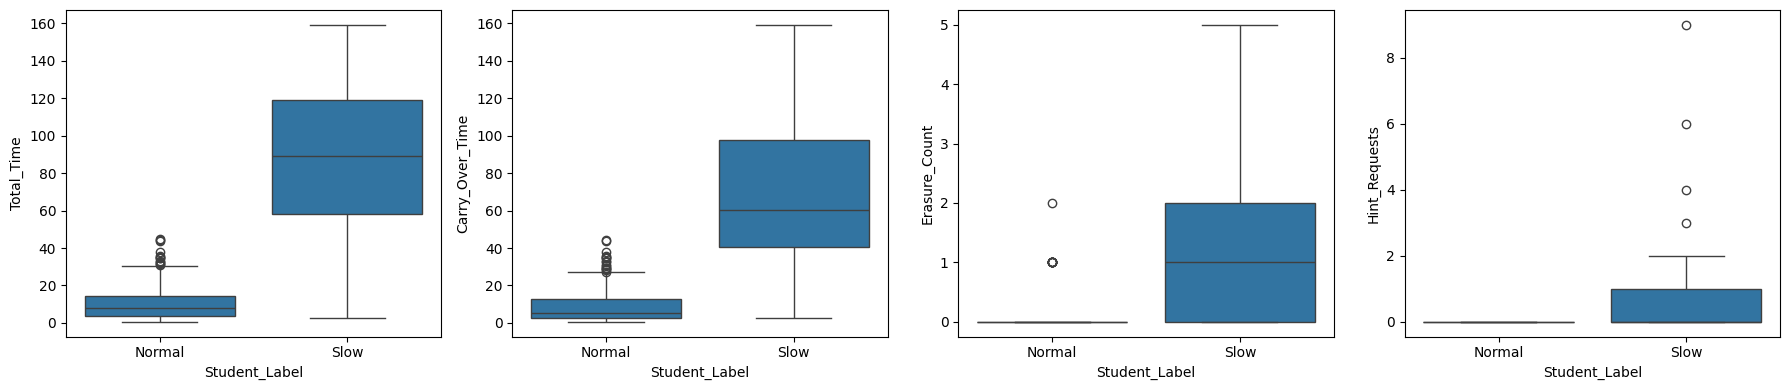

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']):
    sns.boxplot(data=df, x='Student_Label', y=col, ax=a)
plt.tight_layout(); plt.show()

##Feature engineering

In [8]:
USE_HINTS = True      # <- change to False and re-run to test without Hint_Requests

data = df.copy()
data['Slow'] = (data['Student_Label'] == 'Slow').astype(int)      # 1 = Slow, 0 = Normal
data['Carry_Ratio'] = data['Carry_Over_Time'] / data['Total_Time']
data['Non_Carry_Time'] = data['Total_Time'] - data['Carry_Over_Time']

num_cols = ['Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time']
if USE_HINTS: num_cols.append('Hint_Requests')
cat_cols = ['Operation_Type']
FEATURES = num_cols + cat_cols

X = data[FEATURES]
y = data['Slow']
print('Features used:', FEATURES)

Features used: ['Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time', 'Hint_Requests', 'Operation_Type']


##Split into train (80%) and test (20%)

In [9]:
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print('Slow share  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train rows: 324 | Test rows: 82
Slow share  train: 0.423  test: 0.427


##  Train the Decision Tree (first version)

In [10]:
def make_model(**tree_params):
    prep = ColumnTransformer([('op', OneHotEncoder(handle_unknown='ignore'), cat_cols)], remainder='passthrough')
    tree = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE, **tree_params)
    return Pipeline([('prep', prep), ('tree', tree)])

dt = make_model(max_depth=6)
dt.fit(X_train, y_train)
print('Trained!')

Trained!


Evaluate on the test set
| Metric | Meaning (for the Slow class) |
|---|---|
| **Accuracy** | % of all predictions that are correct |
| **Precision** | Of the students predicted Slow, how many really are Slow |
| **Recall** | Of the truly Slow students, how many we caught (missed ones hurt most) |
| **F1** | Balance between Precision and Recall |
| **Specificity** | Of the truly Normal students, how many we correctly called Normal |
| **ROC-AUC** | How well the model ranks Slow above Normal (1.0 = perfect, 0.5 = guessing) |
| **MCC** | Overall quality for imbalanced data (1 = perfect, 0 = random) |

In [11]:
def evaluate(model, X_, y_, title=''):
    pred = model.predict(X_)
    prob = model.predict_proba(X_)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_, pred).ravel()
    m = {'Accuracy': accuracy_score(y_, pred), 'Balanced Accuracy': balanced_accuracy_score(y_, pred),
         'Precision': precision_score(y_, pred, zero_division=0), 'Recall': recall_score(y_, pred),
         'F1': f1_score(y_, pred), 'Specificity': tn / (tn + fp), 'ROC-AUC': roc_auc_score(y_, prob),
         'MCC': matthews_corrcoef(y_, pred)}
    print(title); display(pd.Series(m, name='score').round(3).to_frame())
    print(f'TP={tp} (slow caught)  FN={fn} (slow missed)  FP={fp} (false alarm)  TN={tn}')
    return m, pred, prob

m1, pred1, prob1 = evaluate(dt, X_test, y_test, '=== Test-set results (first tree) ===')

=== Test-set results (first tree) ===


,score
Accuracy,0.963
Balanced Accuracy,0.957
Precision,1.000
Recall,0.914
F1,0.955
Specificity,1.000
ROC-AUC,0.941
MCC,0.927


TP=32 (slow caught)  FN=3 (slow missed)  FP=0 (false alarm)  TN=47


              precision    recall  f1-score   support

      Normal       0.94      1.00      0.97        47
        Slow       1.00      0.91      0.96        35

    accuracy                           0.96        82
   macro avg       0.97      0.96      0.96        82
weighted avg       0.97      0.96      0.96        82



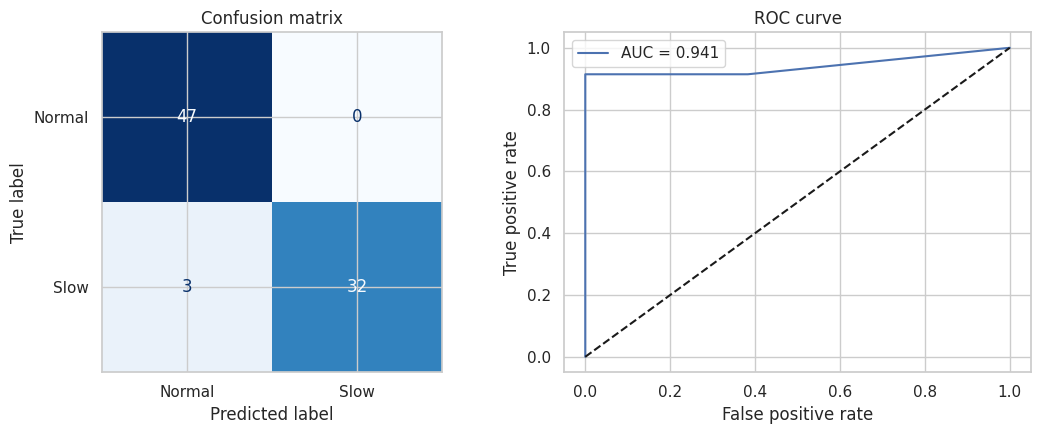

In [12]:
print(classification_report(y_test, pred1, target_names=['Normal', 'Slow']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred1), display_labels=['Normal', 'Slow']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix')
fpr, tpr, _ = roc_curve(y_test, prob1)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, prob1):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate'); ax[1].legend()
plt.tight_layout(); plt.show()

In [13]:
# Overfitting check: a big gap between train and test means the tree memorised the training data
print('Train accuracy:', round(accuracy_score(y_train, dt.predict(X_train)), 3))
print('Test  accuracy:', round(accuracy_score(y_test,  dt.predict(X_test)), 3))
print('Train F1      :', round(f1_score(y_train, dt.predict(X_train)), 3))
print('Test  F1      :', round(f1_score(y_test,  dt.predict(X_test)), 3))

Train accuracy: 0.969
Test  accuracy: 0.963
Train F1      : 0.963
Test  F1      : 0.955


## Cross-validation

In [14]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
res = cross_validate(make_model(max_depth=6), X_train, y_train, cv=cv, scoring=scoring)
cv_table = pd.DataFrame({k: [res[f'test_{k}'].mean(), res[f'test_{k}'].std()] for k in scoring}, index=['mean', 'std']).T.round(3)
cv_table

,mean,std
accuracy,0.910,0.046
precision,0.915,0.068
recall,0.876,0.096
f1,0.891,0.057
roc_auc,0.928,0.051


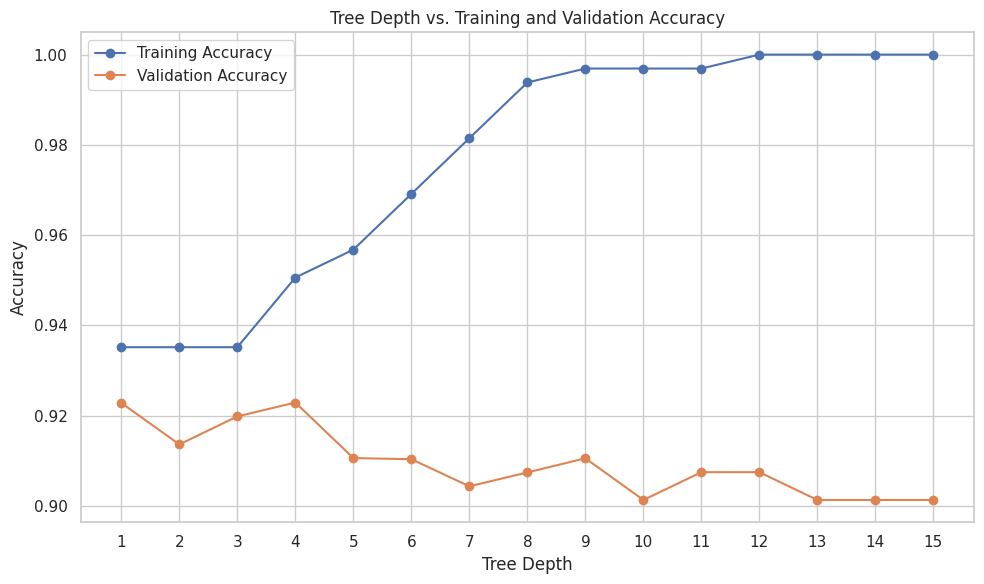

In [15]:

import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score

# Test different tree depths
depths = range(1, 16)

train_accuracy = []
validation_accuracy = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for depth in depths:
    model = make_model(max_depth=depth)

    # Training accuracy
    model.fit(X_train, y_train)
    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    train_accuracy.append(train_acc)

    # Cross-validated accuracy on training data
    scores = cross_validate(
        make_model(max_depth=depth),
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )
    validation_accuracy.append(scores['test_score'].mean())

# Draw graph
plt.figure(figsize=(10, 6))
plt.plot(
    list(depths), train_accuracy,
    marker='o', label='Training Accuracy'
)
plt.plot(
    list(depths), validation_accuracy,
    marker='o', label='Validation Accuracy'
)

plt.xlabel('Tree Depth')
plt.ylabel('Accuracy')
plt.title('Tree Depth vs. Training and Validation Accuracy')
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [16]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    'tree__max_depth': range(1, 16)
}

grid_search = GridSearchCV(
    make_model(),
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['tree__max_depth']

print('Best depth:', best_depth)
print('Best CV accuracy:', round(grid_search.best_score_, 3))


Best depth: 4
Best CV accuracy: 0.923


In [17]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    'tree__max_depth': range(1, 16)
}

grid_search = GridSearchCV(
    make_model(),
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['tree__max_depth']

print('Best depth:', best_depth)
print('Best CV accuracy:', round(grid_search.best_score_, 3))


Best depth: 4
Best CV accuracy: 0.923


##  Tune the tree

In [18]:
TUNE_SCORING = 'f1'
param_grid = {
    'tree__max_depth':        [2, 3, 4, 5, 6, 8],
    'tree__min_samples_leaf': [1, 3, 5, 10],
    'tree__criterion':        ['gini', 'entropy'],
}
search = GridSearchCV(make_model(), param_grid, cv=cv, scoring=TUNE_SCORING, n_jobs=-1)
search.fit(X_train, y_train)
print('Best settings :', search.best_params_)
print(f'Best CV {TUNE_SCORING}  :', round(search.best_score_, 3))
best_dt = search.best_estimator_

Best settings : {'tree__criterion': 'gini', 'tree__max_depth': 4, 'tree__min_samples_leaf': 1}
Best CV f1  : 0.902


In [19]:
m2, pred2, prob2 = evaluate(best_dt, X_test, y_test, '=== Test-set results (tuned tree) ===')

compare = pd.DataFrame({'First tree (depth 6)': m1, 'Tuned tree': m2}).round(3)
compare

=== Test-set results (tuned tree) ===


,score
Accuracy,0.976
Balanced Accuracy,0.971
Precision,1.000
Recall,0.943
F1,0.971
Specificity,1.000
ROC-AUC,0.982
MCC,0.951


TP=33 (slow caught)  FN=2 (slow missed)  FP=0 (false alarm)  TN=47


,First tree (depth 6),Tuned tree
Accuracy,0.963,0.976
Balanced Accuracy,0.957,0.971
Precision,1.000,1.000
Recall,0.914,0.943
F1,0.955,0.971
Specificity,1.000,1.000
ROC-AUC,0.941,0.982
MCC,0.927,0.951


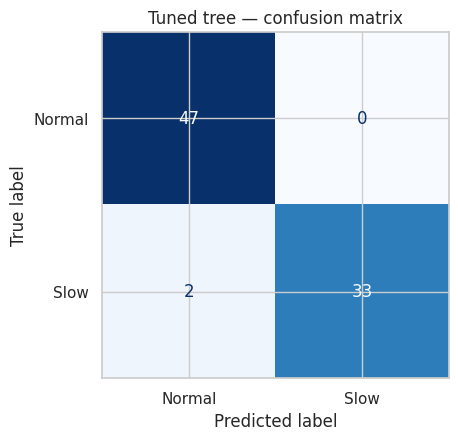

              precision    recall  f1-score   support

      Normal       0.96      1.00      0.98        47
        Slow       1.00      0.94      0.97        35

    accuracy                           0.98        82
   macro avg       0.98      0.97      0.97        82
weighted avg       0.98      0.98      0.98        82



In [20]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred2), display_labels=['Normal', 'Slow']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Tuned tree — confusion matrix'); plt.show()
print(classification_report(y_test, pred2, target_names=['Normal', 'Slow']))

## visual diagram of the tree

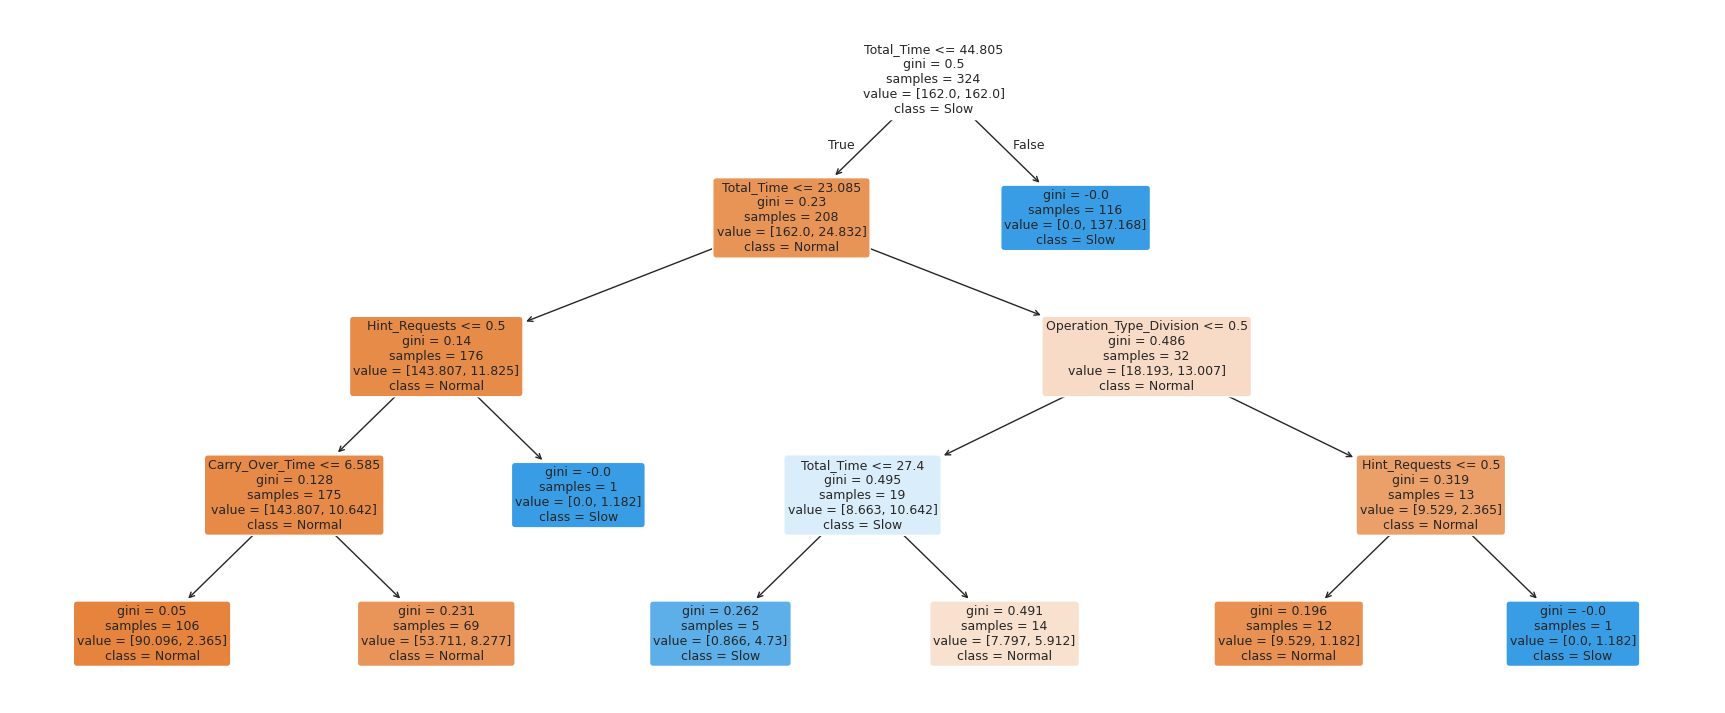

In [21]:
names = [n.split('__')[-1] for n in best_dt.named_steps['prep'].get_feature_names_out()]
tree = best_dt.named_steps['tree']

plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=names, class_names=['Normal', 'Slow'], filled=True, rounded=True, fontsize=9)
plt.show()

In [22]:
print(export_text(tree, feature_names=names))

|--- Total_Time <= 44.81
|   |--- Total_Time <= 23.09
|   |   |--- Hint_Requests <= 0.50
|   |   |   |--- Carry_Over_Time <= 6.58
|   |   |   |   |--- class: 0
|   |   |   |--- Carry_Over_Time >  6.58
|   |   |   |   |--- class: 0
|   |   |--- Hint_Requests >  0.50
|   |   |   |--- class: 1
|   |--- Total_Time >  23.09
|   |   |--- Operation_Type_Division <= 0.50
|   |   |   |--- Total_Time <= 27.40
|   |   |   |   |--- class: 1
|   |   |   |--- Total_Time >  27.40
|   |   |   |   |--- class: 0
|   |   |--- Operation_Type_Division >  0.50
|   |   |   |--- Hint_Requests <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Hint_Requests >  0.50
|   |   |   |   |--- class: 1
|--- Total_Time >  44.81
|   |--- class: 1



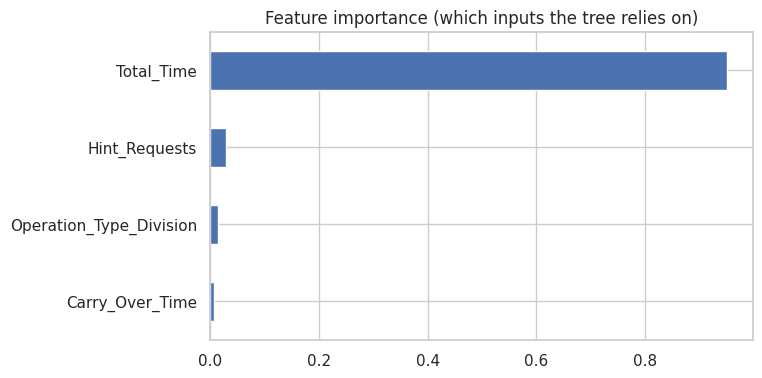

In [23]:
imp = pd.Series(tree.feature_importances_, index=names).sort_values()
imp[imp > 0].plot(kind='barh', figsize=(7, 4), title='Feature importance (which inputs the tree relies on)')
plt.show()

# Final check, save and download

In [24]:
import os, json, joblib, warnings
THRESHOLD = 0.5       # P(Slow) at or above this value => "Slow"

final_model = make_model(**{k.replace('tree__', ''): v for k, v in search.best_params_.items()})
final_model.fit(X, y)

os.makedirs('export', exist_ok=True)
joblib.dump(final_model, 'export/dt_slow_learner_model.joblib')

import sklearn
meta = {'model': 'DecisionTreeClassifier', 'positive_class': 'Slow', 'threshold': THRESHOLD, 'use_hints': USE_HINTS,
        'best_params': search.best_params_, 'features_required_in_order': FEATURES,
        'raw_inputs': ['Operation_Type', 'Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Hint_Requests'],
        'operation_types': sorted(df['Operation_Type'].unique().tolist()),
        'test_metrics': {k: round(v, 4) for k, v in m2.items()}, 'sklearn_version': sklearn.__version__}
json.dump(meta, open('export/dt_model_metadata.json', 'w'), indent=2)
print(json.dumps(meta, indent=2))

{
  "model": "DecisionTreeClassifier",
  "positive_class": "Slow",
  "threshold": 0.5,
  "use_hints": true,
  "best_params": {
    "tree__criterion": "gini",
    "tree__max_depth": 4,
    "tree__min_samples_leaf": 1
  },
  "features_required_in_order": [
    "Total_Time",
    "Carry_Over_Time",
    "Erasure_Count",
    "Carry_Ratio",
    "Non_Carry_Time",
    "Hint_Requests",
    "Operation_Type"
  ],
  "raw_inputs": [
    "Operation_Type",
    "Total_Time",
    "Carry_Over_Time",
    "Erasure_Count",
    "Hint_Requests"
  ],
  "operation_types": [
    "Addition",
    "Division",
    "Multiplication",
    "Subtraction"
  ],
  "test_metrics": {
    "Accuracy": 0.9756,
    "Balanced Accuracy": 0.9714,
    "Precision": 1.0,
    "Recall": 0.9429,
    "F1": 0.9706,
    "Specificity": 1.0,
    "ROC-AUC": 0.9818,
    "MCC": 0.951
  },
  "sklearn_version": "1.7.2"
}


In [25]:
# Try the saved model exactly as your backend will use it
def prepare_input(op, total_time, carry_time, erasures, hints=0):
    row = {'Operation_Type': op, 'Total_Time': total_time, 'Carry_Over_Time': carry_time, 'Erasure_Count': erasures,
           'Hint_Requests': hints, 'Carry_Ratio': carry_time / total_time if total_time else 0,
           'Non_Carry_Time': total_time - carry_time}
    return pd.DataFrame([row])[meta['features_required_in_order']]

loaded = joblib.load('export/dt_slow_learner_model.joblib')
for case in [('Addition', 2.1, 2.1, 0, 0), ('Division', 70.0, 40.0, 2, 3)]:
    p = loaded.predict_proba(prepare_input(*case))[0, 1]
    print(case, '-> P(Slow) =', round(p, 3), '->', 'Slow' if p >= meta['threshold'] else 'Normal')

('Addition', 2.1, 2.1, 0, 0) -> P(Slow) = 0.021 -> Normal
('Division', 70.0, 40.0, 2, 3) -> P(Slow) = 1.0 -> Slow


In [26]:
import shutil
shutil.make_archive('dt_export', 'zip', 'export')
try:
    from google.colab import files
    files.download('dt_export.zip')
except ImportError:
    print('Saved dt_export.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import pandas as pd

def predict_student(operation, total_time, carry_over, erasures=0, hints=0):
    """
    Formats the input with the exact engineered features
    expected by your ColumnTransformer pipeline.
    """
    # 1. Calculate the engineered features your pipeline requires
    carry_ratio = carry_over / total_time if total_time > 0 else 0
    non_carry_time = total_time - carry_over

    # 2. Build the dictionary using the EXACT column names from your notebook
    input_data = {
        'Operation_Type': str(operation).strip().capitalize(),
        'Total_Time': float(total_time),
        'Carry_Over_Time': float(carry_over),
        'Carry_Ratio': float(carry_ratio),
        'Non_Carry_Time': float(non_carry_time),
        'Erasure_Count': int(erasures),
        'Hint_Requests': int(hints)
    }

    # 3. Convert to a 1-row DataFrame
    df_input = pd.DataFrame([input_data])

    # 4. Predict using your trained pipeline
    # NOTE: If your model is named something else (like 'best_dt'), change it here
    prediction = final_model.predict(df_input)[0]

    # Get probability
    try:
        # Assumes Class 1 (index 1) is 'Slow'
        prob = final_model.predict_proba(df_input)[0][1] * 100
        prob_text = f"Confidence: {prob:.1f}%"
    except:
        prob_text = ""

    # Format the output label
    label = "SLOW" if str(prediction) == '1' or str(prediction).lower() == 'slow' else "NORMAL"

    print(f"--- Prediction for {input_data['Operation_Type']} ---")
    print(f"Time: {total_time}s | Carry: {carry_over}s | Erasures: {erasures} | Hints: {hints}")
    print(f"Result: {label} Learner ({prob_text})\n")

# ============================================================
# ---- TEST YOUR OWN INPUTS HERE ----
# ============================================================

predict_student(operation='Division', total_time=48.5, carry_over=30.2,erasures=5)
predict_student(operation='Addition', total_time=44.91, carry_over=5.4,erasures=0,hints=0)

--- Prediction for Division ---
Time: 48.5s | Carry: 30.2s | Erasures: 5 | Hints: 0
Result: SLOW Learner (Confidence: 100.0%)

--- Prediction for Addition ---
Time: 44.91s | Carry: 5.4s | Erasures: 0 | Hints: 0
Result: SLOW Learner (Confidence: 100.0%)

